# Exploratory Data Analysis (EDA)

The objective of this analysis is to understand the distribution of house prices in Chennai, identify important factors affecting property prices, detect missing values, and uncover potential outliers before model development.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Data

In [4]:
df = pd.read_csv("Data/chennai_house_market_data_1.csv")

## Data Inception

In [5]:
df.head()

,price,area,status,bhk,bathroom,age,location,builder
0,37.49,872,Ready to move,2,NaN,1.0,Sembakkam,MP Developers
1,93.54,1346,Under Construction,3,2.0,NaN,Selaiyur,DAC Promoters
2,151.00,2225,Under Construction,3,NaN,0.0,Mogappair,Casagrand Builder Private Limited
3,49.00,1028,Ready to move,2,2.0,3.0,Ambattur,Dugar Housing Builders
4,42.28,588,Under Construction,2,1.0,0.0,Pallavaram,Radiance Realty Developers India Ltd


In [6]:
df.tail()

,price,area,status,bhk,bathroom,age,location,builder
2615,27.5,750,Ready to move,2,2.0,3.0,Veppampattu,Velan Housing Properties
2616,27.5,750,Ready to move,2,2.0,3.0,Veppampattu,Velan Housing Properties
2617,30.0,800,Ready to move,2,2.0,3.0,Veppampattu,Velan Housing Properties
2618,31.5,850,Ready to move,2,2.0,3.0,Veppampattu,Velan Housing Properties
2619,34.0,900,Ready to move,2,2.0,3.0,Veppampattu,Velan Housing Properties


In [8]:
df.sample(5)

,price,area,status,bhk,bathroom,age,location,builder
545,221.00,1250,Under Construction,3,NaN,0.0,Anna Nagar,India Builders Limited
1242,40.42,825,Ready to move,2,2.0,NaN,Kolapakkam,HM Homes
161,48.69,994,Under Construction,2,NaN,0.0,Madhavaram,Radiance Realty Developers India Ltd
559,33.42,1013,Under Construction,2,NaN,0.0,Thaiyur,Shatapatri Estates Pvt Ltd
1290,130.00,1330,Ready to move,2,3.0,NaN,Chetpet,MEHTA REAL ESTATE CHENNAI LLP


In [9]:
df.shape

(2620, 8)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2620 entries, 0 to 2619
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   price     2620 non-null   float64
 1   area      2620 non-null   int64  
 2   status    2620 non-null   str    
 3   bhk       2620 non-null   int64  
 4   bathroom  1403 non-null   float64
 5   age       1729 non-null   float64
 6   location  2620 non-null   str    
 7   builder   2620 non-null   str    
dtypes: float64(3), int64(2), str(3)
memory usage: 268.4 KB


## Dataset Overview

The dataset contains residential property records from various locations across Chennai. Each record includes property characteristics such as area, number of bedrooms, bathrooms, property age, builder information, and price.

In [16]:
df.describe()

,price,area,bhk,bathroom,age
count,2620.000000,2620.000000,2620.000000,1403.000000,1729.000000
mean,93.834683,1282.925191,2.443893,2.359230,1.355119
std,113.609349,692.566319,0.811984,0.844951,2.102682
min,12.830000,300.000000,1.000000,1.000000,0.000000
25%,42.000000,877.000000,2.000000,2.000000,0.000000
50%,61.735000,1091.500000,2.000000,2.000000,0.000000
75%,90.000000,1471.250000,3.000000,3.000000,3.000000
max,1422.000000,6700.000000,8.000000,7.000000,32.000000


## Statistical Summary

A statistical summary was generated to understand the distribution of numerical features and identify potential anomalies.

In [17]:
df.isnull().sum()

price          0
area           0
status         0
bhk            0
bathroom    1217
age          891
location       0
builder        0
dtype: int64

<Axes: >

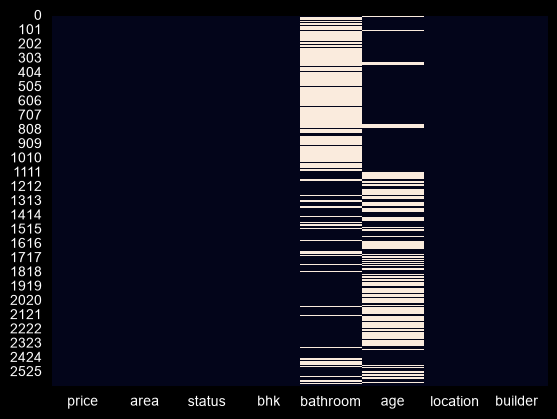

In [20]:
sns.heatmap(df.isnull(), cbar=False)

## Missing Value Analysis

The missing value analysis reveals that the dataset is largely complete, with missing values concentrated only in the **bathroom** and **age** features.

- Bathroom contains **1,217 missing values**.
- Age contains **891 missing values**.
- Price, area, status, BHK, location, and builder contain **no missing values**.

The heatmap confirms that missing values are primarily distributed across the bathroom and age columns rather than affecting the entire dataset uniformly. Since these features may influence property valuation, appropriate imputation techniques will be required before model training.

This analysis highlights the importance of preprocessing, particularly for the bathroom and age attributes, to ensure model reliability and prevent information loss.

## Target Variable Analysis (Price)

<Axes: xlabel='price', ylabel='Count'>

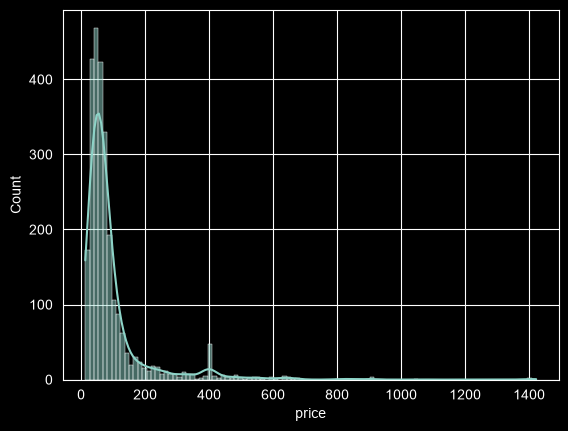

In [21]:
sns.histplot(df["price"], kde=True)

### Observation:
The distribution of house prices is highly right-skewed, indicating that most properties are concentrated within the lower and mid-price ranges, while a relatively small number of properties are priced significantly higher.

The histogram shows that the majority of properties are priced below approximately 150 lakhs, with frequency decreasing rapidly as property prices increase. The long right tail suggests the presence of premium and luxury properties, some exceeding 1000 lakhs.

This skewed distribution indicates the existence of extreme values and potential outliers within the dataset. These observations warrant further investigation during preprocessing and outlier analysis to determine their impact on model performance.

Overall, the distribution suggests that Chennai's housing market contains a large concentration of moderately priced properties alongside a small number of high-value luxury properties.
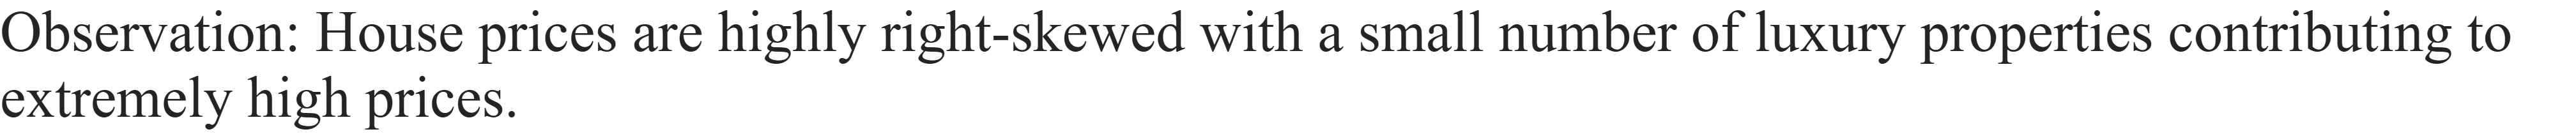

<Axes: xlabel='price'>

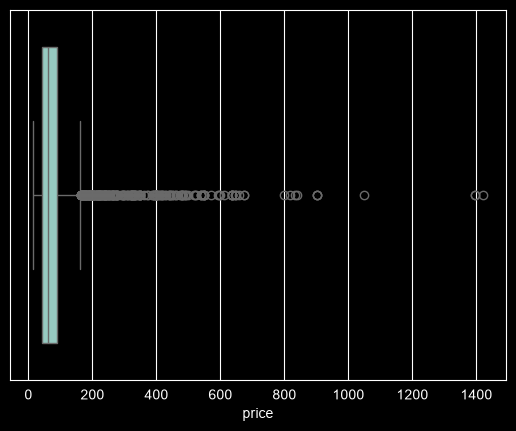

In [22]:
sns.boxplot(x=df["price"])

### Observation:
The boxplot reveals the presence of numerous extreme values in the house price distribution. While the majority of properties are concentrated within a relatively narrow price range, several properties extend far beyond the upper whisker, indicating potential outliers.

Most property prices appear to be clustered below approximately 150 lakhs, whereas a small number of premium properties are priced significantly higher, with some exceeding 1000 lakhs. These observations are consistent with the right-skewed distribution observed in the price histogram.

The large number of points beyond the upper whisker suggests substantial variability in the Chennai housing market, likely driven by luxury properties, premium locations, and high-end residential developments.

These extreme observations may influence statistical measures and machine learning models, making further outlier investigation necessary during the preprocessing stage.

<Axes: xlabel='area', ylabel='price'>

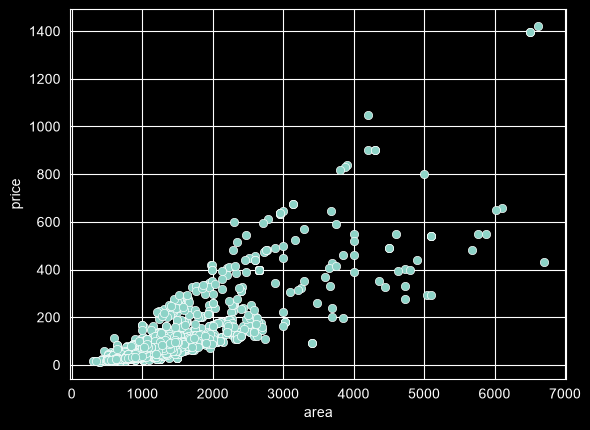

In [23]:
sns.scatterplot(
    x="area",
    y="price",
    data=df
)

### Observation:
The scatter plot indicates a strong positive relationship between property area and house price. As the area of a property increases, its price generally tends to increase as well.

Most properties are concentrated between approximately **500 and 2,500 square feet**, with prices largely below **300 lakhs**. The density of points in this region suggests that mid-sized residential properties form the majority of the dataset.

A number of properties with exceptionally large areas and very high prices are also visible. These observations appear far from the main cluster and may represent luxury properties or potential outliers within the dataset.

The increasing trend between area and price is further supported by the correlation analysis, where **area exhibits the strongest positive correlation with price (0.82)** among all numerical features. This suggests that property area is one of the most important factors influencing house prices and is expected to play a significant role in the predictive model.

<Axes: xlabel='bathroom', ylabel='price'>

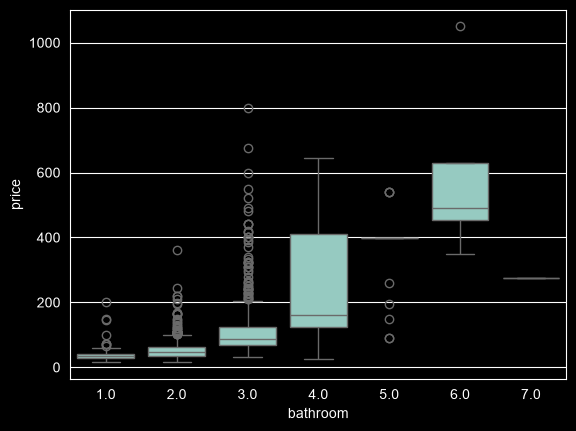

In [24]:
sns.boxplot(
    x="bathroom",
    y="price",
    data=df
)

### Observation

The boxplot indicates a positive relationship between the number of bathrooms and house price. In general, properties with a higher number of bathrooms tend to have higher median prices.

Properties with 1 and 2 bathrooms are concentrated in the lower price ranges, while properties with 3, 4, and 6 bathrooms are associated with substantially higher prices. The median price generally increases as the number of bathrooms increases, suggesting that bathroom count is an important factor influencing property value.

The spread of prices also becomes wider for larger bathroom counts, indicating greater price variability among premium properties. Several high-value outliers are visible across different bathroom categories, particularly among properties with 3, 4, and 6 bathrooms.

This observation is supported by the correlation analysis, where bathroom count exhibits a moderate positive correlation with price (**0.69**), making it one of the more influential numerical features in the dataset.

<Axes: xlabel='age', ylabel='price'>

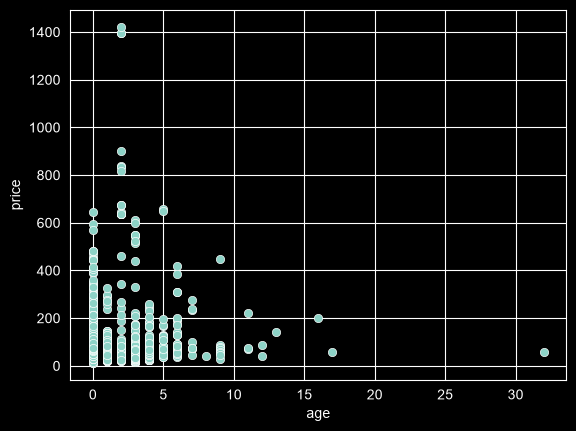

In [25]:
sns.scatterplot(
    x="age",
    y="price",
    data=df
)

### Observation

The scatter plot shows a very weak relationship between property age and house price. Unlike area, BHK, and bathroom count, no clear upward or downward trend is visible as age increases.

Most properties are concentrated within the **0 to 5 years** age range, indicating that the dataset is dominated by relatively new residential properties. House prices within this range vary significantly, suggesting that factors such as location, builder, and property size have a much stronger influence on price than age.

A few older properties are present in the dataset; however, they do not exhibit a consistent pricing pattern. Both low-priced and high-priced properties appear across different age groups.

This observation is supported by the correlation analysis, where age has an extremely weak correlation with price (**0.017**), indicating that age contributes very little predictive information. Therefore, age may not be a strong feature for house price prediction and should be evaluated further during model development.

## Correlation Analysis



In [26]:
df[["area","bhk","bathroom","age","price"]].corr()

,area,bhk,bathroom,age,price
area,1.000000,0.785474,0.774909,0.039704,0.823508
bhk,0.785474,1.000000,0.861279,-0.025189,0.617898
bathroom,0.774909,0.861279,1.000000,0.033928,0.687380
age,0.039704,-0.025189,0.033928,1.000000,0.016594
price,0.823508,0.617898,0.687380,0.016594,1.000000


<Axes: >

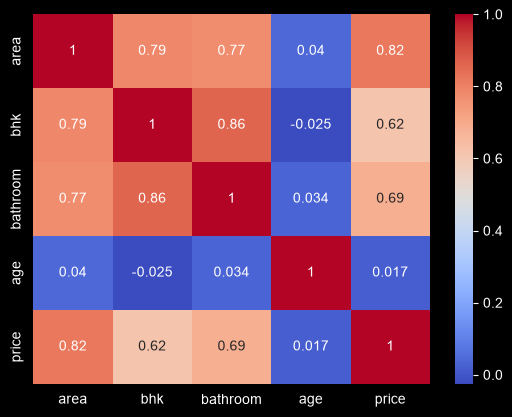

In [27]:
sns.heatmap(
    df[["area","bhk","bathroom","age","price"]].corr(),
    annot=True,
    cmap="coolwarm"
)

## Observation

The correlation heatmap reveals that property area has the strongest positive relationship with house price (correlation = 0.82), indicating that larger properties generally command higher prices.

Bathroom count (0.69) and BHK count (0.62) also exhibit moderate positive correlations with price, suggesting that larger residential configurations tend to be more expensive.

Additionally, area, BHK, and bathroom count are strongly correlated with one another. For example, BHK and bathroom count show a high correlation of 0.86, which is expected since houses with more bedrooms typically require more bathrooms.

In contrast, the age feature demonstrates an extremely weak correlation with price (0.017), indicating that property age has little direct influence on house prices within this dataset.

Overall, area, BHK, and bathroom count appear to be the most influential numerical features for house price prediction, while age contributes minimal predictive value.
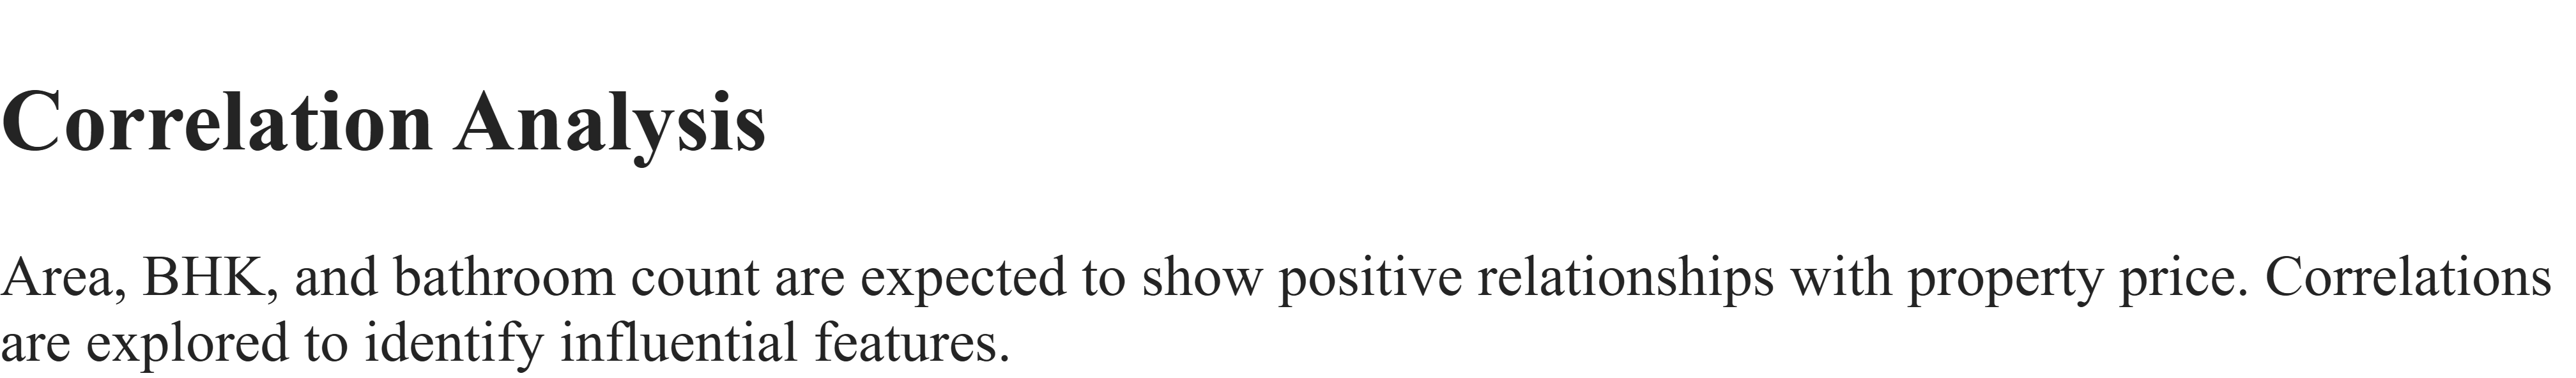

## Categorical Feature Analysis

In [48]:
location_stats = (
    df.groupby("location")["price"]
      .agg(["count", "mean"])
)

location_stats = location_stats[
    location_stats["count"] >= 5
]

location_stats.sort_values(
    "mean",
    ascending=False
).head(10)

,count,mean
location,,
Royapettah,24,624.500000
Alwarpet,11,529.363636
T Nagar,20,370.230000
West Mambalam,47,356.744681
Kotturpuram,20,342.650000
Kanathur Reddikuppam,9,309.665556
Kilpauk,9,301.222222
Adyar,11,293.636364
Egmore,7,293.285714


In [30]:
df.groupby("builder")["price"].mean().sort_values(ascending=False)

builder
Shree sakthivel realestate                        1050.000000
Vinay Asrani                                       703.208333
Lifestyle Housing                                  549.500000
Mayances Construction and Engineering Services     467.500000
Puravankara Limited                                427.333333
                                                     ...     
viswaraj                                            26.601887
JD Properties                                       26.324333
Vijay Raja Homes Private Limited                    22.726667
chris                                               19.800000
Baashyaam Group                                     19.455556
Name: price, Length: 135, dtype: float64

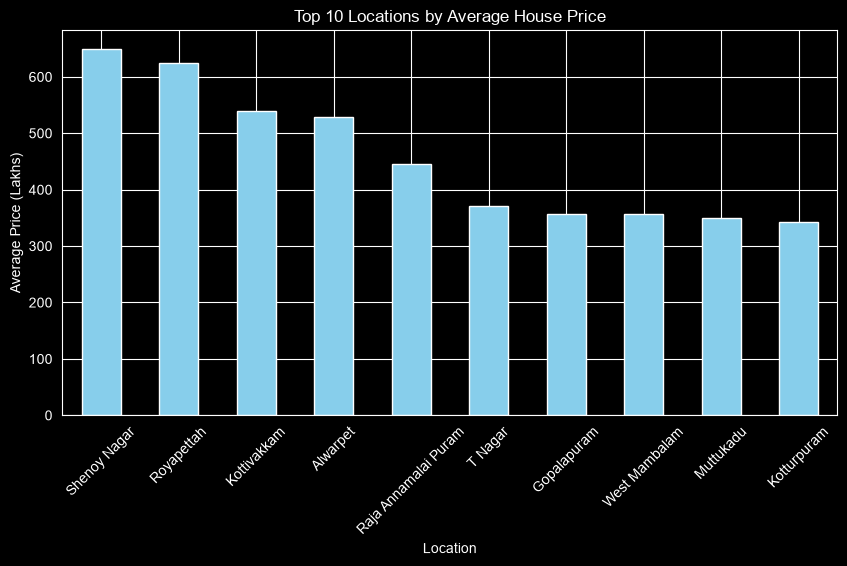

In [49]:
top_locations = (
    df.groupby("location")["price"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,5))

top_locations.plot(
    kind="bar",
    color="skyblue"
)

plt.title("Top 10 Locations by Average House Price")
plt.xlabel("Location")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=45)

plt.show()

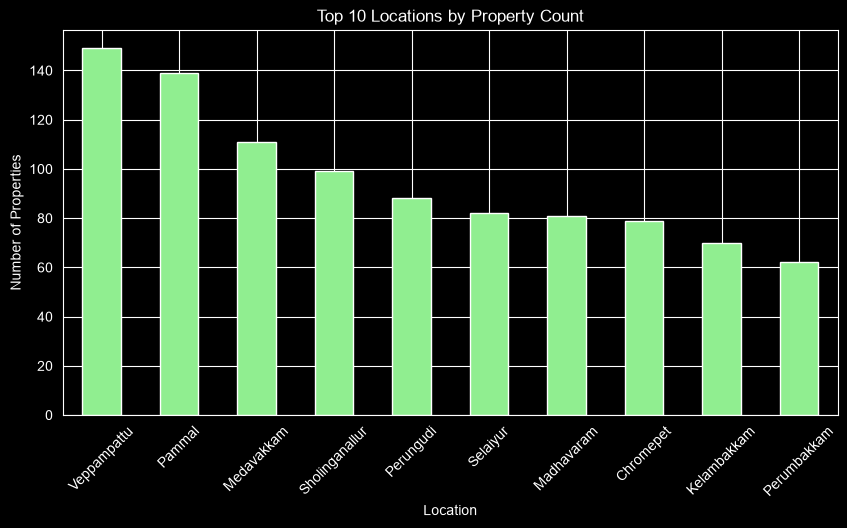

In [50]:
top_locations_count = (
    df["location"]
      .value_counts()
      .head(10)
)

plt.figure(figsize=(10,5))

top_locations_count.plot(
    kind="bar",
    color="lightgreen"
)

plt.title("Top 10 Locations by Property Count")
plt.xlabel("Location")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)

plt.show()

### Observation:

Premium localities such as Shenoy Nagar, Royapettah, Kottivakkam, and Alwarpet exhibit the highest average property prices in the dataset. However, these averages should be interpreted with caution because some locations may contain only a small number of property records. Further analysis using location-wise property counts is recommended before drawing definitive conclusions.

<Axes: xlabel='builder'>

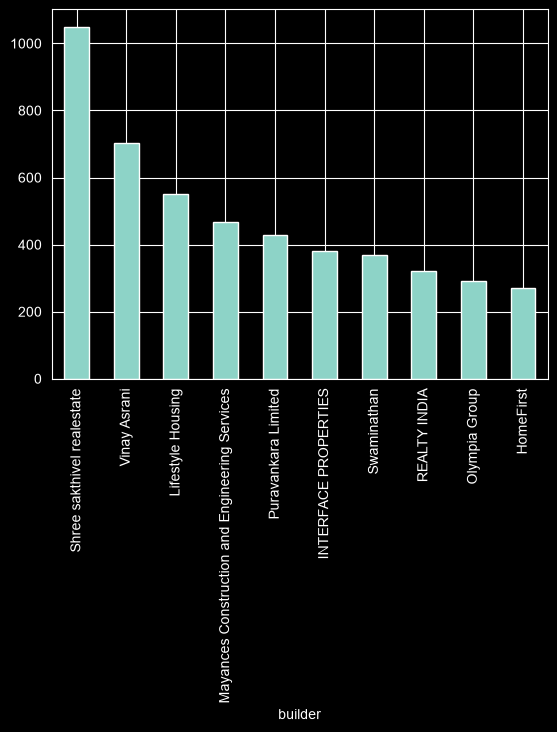

In [31]:
top_builders = (
    df.groupby("builder")["price"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

top_builders.plot(kind="bar")


In [51]:
builder_stats = (
    df.groupby("builder")["price"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

builder_stats.head(10)

,count,mean
builder,,
Shree sakthivel realestate,1,1050.000000
Vinay Asrani,24,703.208333
Lifestyle Housing,2,549.500000
Mayances Construction and Engineering Services,4,467.500000
Puravankara Limited,3,427.333333
INTERFACE PROPERTIES,8,381.375000
Swaminathan,2,367.500000
REALTY INDIA,4,321.750000
Olympia Group,15,290.729333


### Observation

Average property prices vary significantly across builders, indicating that builder reputation, project quality, amenities, and target market segments influence house prices.

Several builders exhibit substantially higher average project prices than others. However, these averages should be interpreted cautiously since some builders may have only a limited number of property listings in the dataset. Despite this limitation, the observed variation suggests that builder information carries meaningful predictive value and should be retained as an input feature for the machine learning model.

<Axes: xlabel='bhk', ylabel='count'>

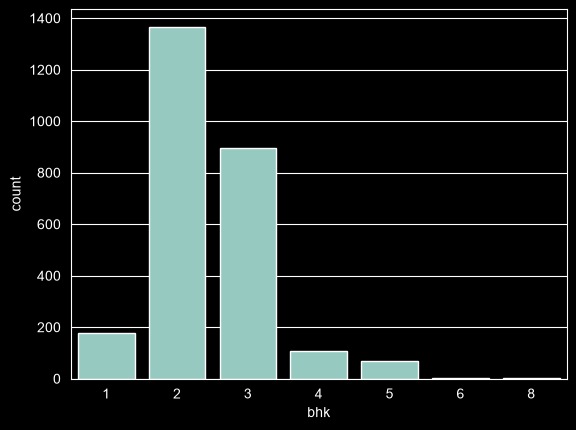

In [37]:
sns.countplot(x="bhk", data=df)

In [47]:
bhk_counts = df["bhk"].value_counts().sort_index()

print(bhk_counts)

bhk
1     177
2    1367
3     895
4     108
5      67
6       4
8       2
Name: count, dtype: int64


### Observation
Most listed properties are 2 BHK and 3 BHK units.
- 2bhk -> 52.17%
- 3bhk -> 34.16%

<Axes: xlabel='status', ylabel='count'>

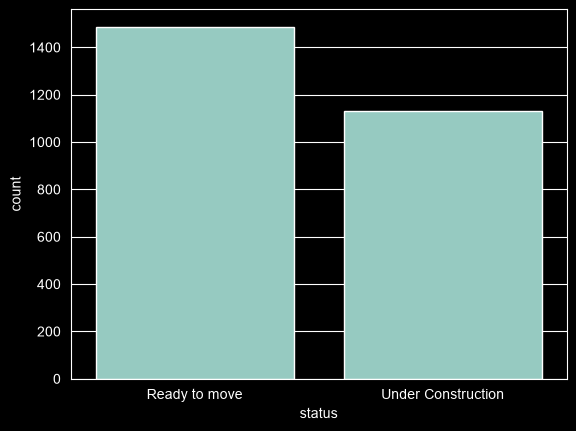

In [38]:
sns.countplot(x="status", data=df)

In [43]:
ready_count = (df['status'] == 'Ready to move').sum()

under_construction_count = (
    df['status'] == 'Under Construction'
).sum()

print(f"Ready to Move: {ready_count}")
print(f"Under Construction: {under_construction_count}")

Ready to Move: 1487
Under Construction: 1133


### Observation
The dataset contains both under-construction and ready-to-move properties, providing a balanced representation of the market.
- Ready to Move : 1487 (56.75%) properties
- Under Construction : 1133 (43.24) properties

## Price Per Square Foot Analysis

In [32]:
df["price_per_sqft"] = df["price"] / df["area"]

<Axes: xlabel='price_per_sqft'>

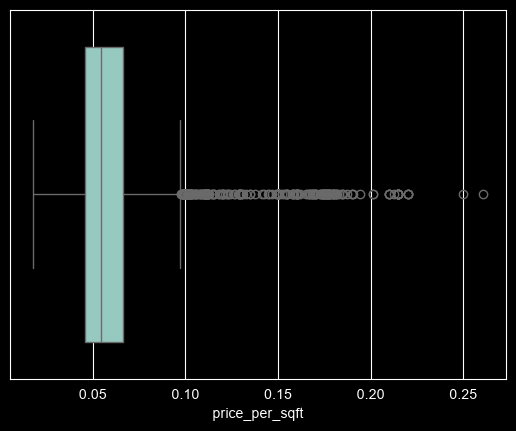

In [33]:
sns.boxplot(x=df["price_per_sqft"])

### Observation

Price per square foot was analyzed to identify extreme property records and potential outliers.### Observation

The Price Per Square Foot distribution exhibits a noticeable right skew with several extreme observations visible beyond the upper whisker of the boxplot.

Most properties are concentrated within a relatively narrow price-per-square-foot range, while a smaller number of properties have significantly higher values. These extreme observations may represent luxury properties, premium locations, or potential data anomalies.

The presence of these outliers suggests that further analysis is required to determine whether they reflect genuine market behavior or should be treated during preprocessing. Consequently, Price Per Square Foot was used as a supporting feature for outlier detection and evaluation during model development.

## Key Insights

1. Property area exhibits the strongest relationship with house price, with a correlation coefficient of 0.82, indicating that larger properties generally command higher prices.

2. Bathroom count and BHK count show moderate positive correlations with price (0.69 and 0.62 respectively), suggesting that larger residential configurations are typically associated with higher property values.

3. Location plays a significant role in determining property prices. Significant variation in average prices across locations indicates the importance of geographical factors in Chennai's housing market.

4. Builder reputation influences property valuation considerably. Certain builders consistently develop premium-priced projects, making builder information an important predictive feature.

5. House prices exhibit a highly right-skewed distribution, with the majority of properties concentrated in lower to mid-price ranges and a relatively small number of premium properties extending the upper tail of the distribution.

6. The dataset contains several high-value properties that appear as outliers. These observations warranted further analysis to assess their impact on model performance and prediction stability.

7. The age feature demonstrated extremely weak predictive power, with a correlation of only 0.017 with price. Additionally, approximately 34% of age values were missing, making it a relatively weak feature for prediction.

8. Missing values were concentrated primarily in the bathroom and age features, while all other attributes were complete. Appropriate imputation strategies were therefore required before model training.

9. Price Per Square Foot varied substantially across properties, highlighting differences in location attractiveness, builder reputation, and housing market segments.

10. EDA findings consistently indicated that area, bathroom count, BHK count, location, and builder were the most influential factors affecting house prices in the dataset.

## Conclusion

The Exploratory Data Analysis provided valuable insights into the structure and characteristics of Chennai's residential housing market. The analysis revealed that property area is the most influential numerical feature affecting house prices, followed by bathroom count and BHK configuration. Additionally, location and builder information were found to be significant determinants of property value.

The analysis also identified substantial variability in house prices across different market segments, along with the presence of premium properties and potential outliers. Missing values were concentrated primarily in the bathroom and age features, requiring appropriate preprocessing strategies before model development.

Further investigation showed that the age feature had a negligible relationship with price and contributed limited predictive value. These findings guided subsequent feature selection decisions and ultimately led to the exclusion of age from the final model.

Overall, the EDA established a strong foundation for preprocessing and model development by identifying the key drivers of house prices, highlighting data quality issues, and uncovering patterns that informed the final machine learning solution for Chennai house price prediction.